<a href="https://colab.research.google.com/github/fiona-crdt/2026_Intro_Python/blob/main/live/part-I/1.6-geospatial-vector-data-environmental-exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Notebook-friendly copy of `part-I/1.6-geospatial-vector-data-environmental-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [3]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# Environmental Exercises

**ℹ️ How to use these exercises**

Attempt each from scratch in the empty code cell. Import geopandas as `gpd`, keep track of the crs at every step, and measure only after reprojecting to a metric crs.

## Exercise 1: Hurricane track analysis

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/nasa-hurricane-florence-2018-09-11.jpg" alt="A satellite view of Hurricane Florence over the Atlantic, a clear eye at the centre of a broad spiral of cloud" width="500">

<em>Hurricane Florence on 11 September 2018, three days before landfall in North Carolina. Image from <a href="https://worldview.earthdata.nasa.gov/">NASA Worldview</a> via <a href="https://commons.wikimedia.org/wiki/File:Florence_2018-09-11_1750Z.jpg">Wikimedia Commons</a>, public domain.</em>


*Can you quickly find out which US states Hurricane Florence passed through using geopandas?*

Apply geopandas to read in the geospatial data, plot, and analyse the track of Hurricane Florence
from 30 August to 18 September 2018. The track is the archived advisory record from the
[National Hurricane Center](https://www.nhc.noaa.gov/); the state boundaries are a
[US Census Bureau](https://www.census.gov/geographies/mapping-files/time-series/geo/carto-boundary-file.html)
cartographic boundary file.

References:

1. [Introduction to GeoPandas](https://geopandas.org/en/stable/getting_started/introduction.html) — geopandas' official website
2. [Geopandas: an introduction](https://autogis-site.readthedocs.io/en/latest/lessons/lesson-2/geopandas-an-introduction.html) — Automating GIS Processes
3. [Use Data for Earth and Environmental Science in Open Source Python](https://www.earthdatascience.org/courses/use-data-open-source-python/)
4. [The Shapely User Manual](https://shapely.readthedocs.io/en/stable/manual.html)
5. [Geospatial Analysis with Python and R](https://kodu.ut.ee/~kmoch/geopython2020/index.html)

In [4]:
# Pre-supplied: download and cache the two real data files.
import pooch

states_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/gz_2010_us_040_00_5m.json",
    known_hash="sha256:7a8c022e063a34a83f35984cde6c81992ece5983f8cc4459ed02e40687739573",
    fname="us_states.geojson",
    path=pooch.os_cache("mlees"),
)
track_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/florence.csv",
    known_hash="sha256:385691583ee41682a1c905e042c56ea362609fb04645934bdda7911c55c8b63f",
    fname="florence.csv",
    path=pooch.os_cache("mlees"),
)

**ℹ️ Where the tools come from**

Every tool the questions need has been demonstrated already. `read_file`, `.plot()`, `GeoDataFrame`,
`gpd.points_from_xy`, `.crs`, `geom_type`, the MultiPolygon type, `.isin()`, `overlay`, `.centroid`,
`to_crs`, `buffer` and the spatial predicates are from this subchapter's lecture; `.head()` and
boolean filtering are from 1.5, and `unique` from 1.5's earthquake exercise. `ax.annotate`, which Q8
uses to label each state, is from 1.4.

**Q1) Import geopandas and pandas.**

Import geopandas as `gpd`, pandas as `pd`, and matplotlib's pyplot as `plt`.

In [5]:
# Import geopandas (as gpd), pandas, and matplotlib
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

**Q2) Read the state boundary file with geopandas' `read_file` function.**

The file is cached at `states_path`. Call the result `country`.

In [6]:
# Read the data with the geopandas function
country = gpd.read_file(states_path)

**Q3) Have a look at the data. What type of geometries does it contain?**

Print the first few rows, and answer the geometry question in a comment.

In [7]:
# Print out the first few lines of the data
country.head()
#contains polygons and multipolygons

,GEO_ID,STATE,NAME,LSAD,CENSUSAREA,geometry
0,0400000US01,01,Alabama,,50645.326,"MULTIPOLYGON (((-88.12466 30.28364, -88.08681 ..."
1,0400000US02,02,Alaska,,570640.950,"MULTIPOLYGON (((-166.10574 53.98861, -166.0752..."
2,0400000US04,04,Arizona,,113594.084,"POLYGON ((-112.53859 37.00067, -112.53454 37.0..."
3,0400000US05,05,Arkansas,,52035.477,"POLYGON ((-94.04296 33.01922, -94.04304 33.079..."
4,0400000US06,06,California,,155779.220,"MULTIPOLYGON (((-122.42144 37.86997, -122.4213..."


**Q4) Have a look at the data on a map using geopandas' `.plot()` method.**

Exclude Alaska and Hawaii using the `NAME` attribute and pandas' `.isin()` method. Specify the
figsize to be 30 x 20.

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

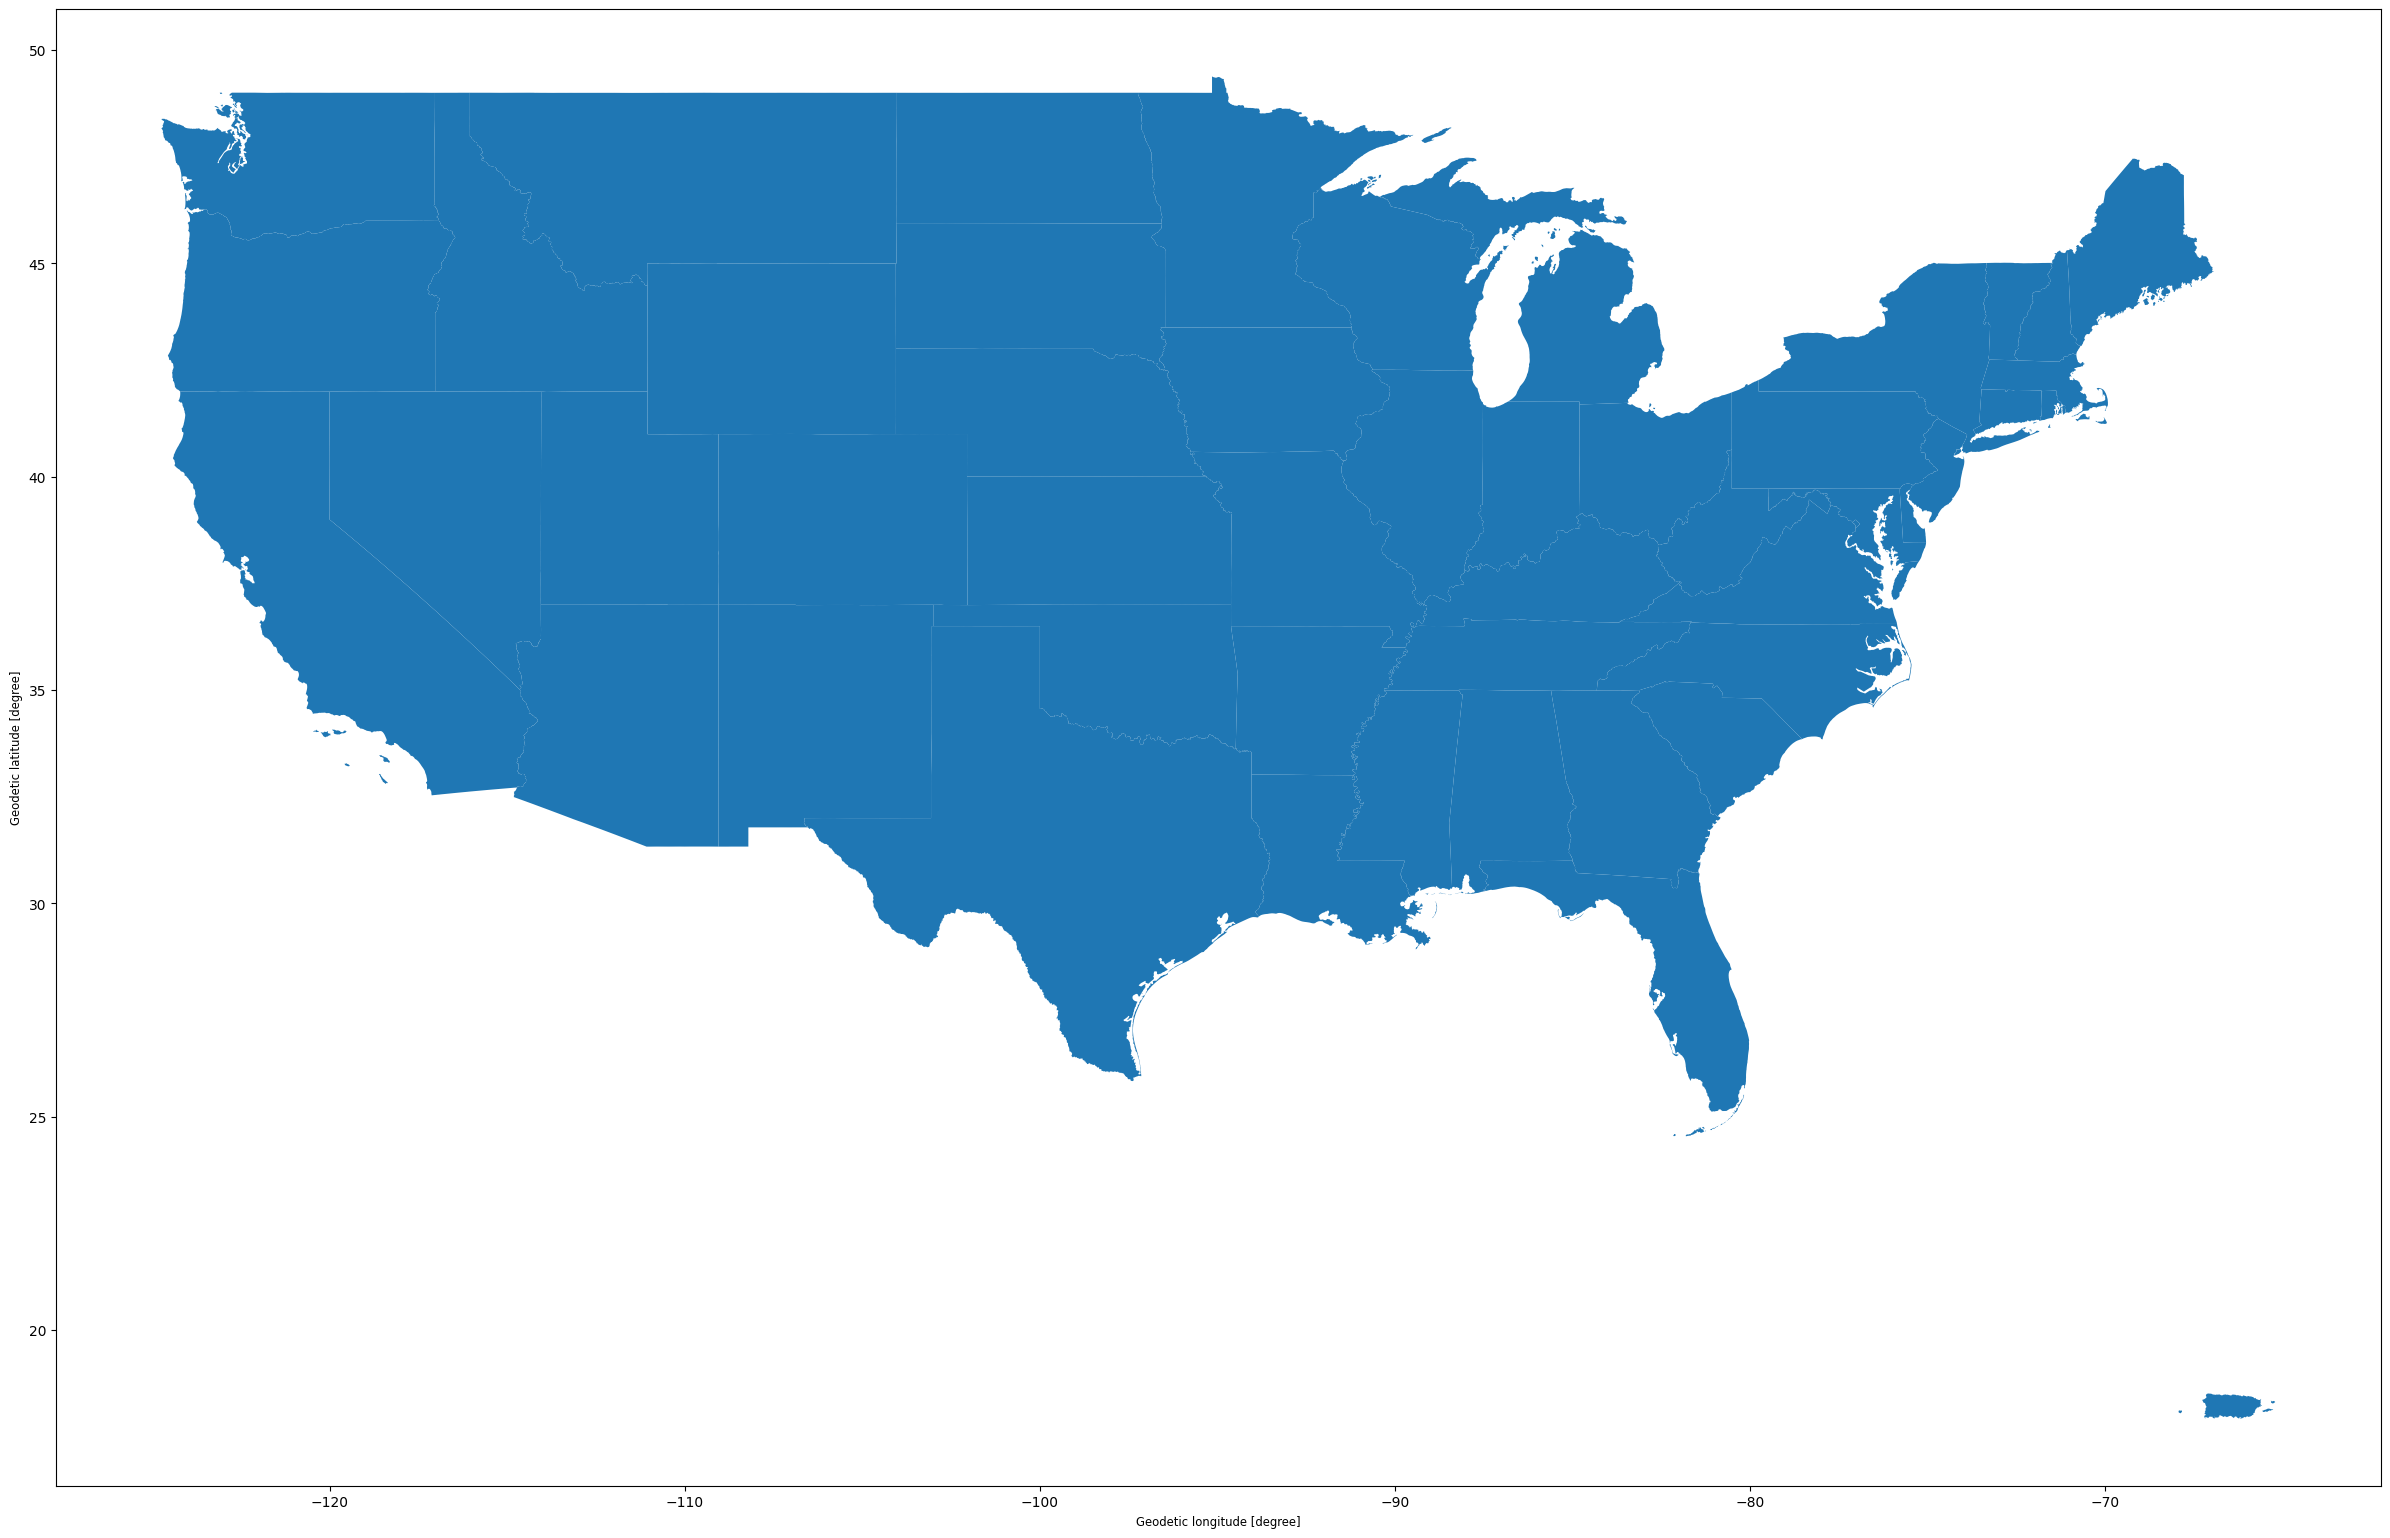

In [8]:
# Plot the US states (Alaska and Hawaii excluded)
country[~country.NAME.isin(["Alaska","Hawaii"])].plot(figsize=(30,20))

In [9]:
# Pre-supplied: read in the hurricane Florence data, drop the advisory bookkeeping columns,
# fix the longitude sign, and have a look at the dataframe.
# The Long column holds a positive "degrees west" magnitude, not a signed longitude -- a common
# quirk of NHC advisory data.
florence = pd.read_csv(track_path)
florence = florence.drop(["AdvisoryNumber", "Forecaster", "Received"], axis=1)
florence["Long"] = 0 - florence["Long"]
florence.head(3)

,Date,Lat,Long,Wind,Pres,Movement,Type,Name
0,08/30/2018 11:00,12.9,-18.4,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six
1,08/30/2018 14:00,12.9,-19.0,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six
2,08/30/2018 17:00,12.9,-19.4,30,1007,W at 9 MPH (280 deg),Potential Tropical Cyclone,Six


**Q5) Create a GeoDataFrame from the `florence` DataFrame.**

Build the geometry column from the `Long` and `Lat` columns with
[`gpd.points_from_xy`](https://geopandas.org/en/stable/docs/reference/api/geopandas.points_from_xy.html),
and call the result `gdf_florence`. Then look at its first few rows.

In [10]:
# Create a geodataframe from the hurricane florence dataframe
gdf_florence = gpd.GeoDataFrame(florence, geometry=gpd.points_from_xy([(florence.Long, florence.Lat)], crs="EPSG:4326"))

TypeError: points_from_xy() missing 1 required positional argument: 'y'

In [11]:
# Create a geodataframe from the hurricane florence dataframe
gdf_florence = gpd.GeoDataFrame(florence, geometry=gpd.points_from_xy(florence.Long, florence.Lat, crs="EPSG:4326"))
gdf_florence.head()

,Date,Lat,Long,Wind,Pres,Movement,Type,Name,geometry
0,08/30/2018 11:00,12.9,-18.4,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-18.4 12.9)
1,08/30/2018 14:00,12.9,-19.0,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-19 12.9)
2,08/30/2018 17:00,12.9,-19.4,30,1007,W at 9 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-19.4 12.9)
3,08/30/2018 20:00,13.1,-20.4,30,1007,W at 11 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-20.4 13.1)
4,08/30/2018 23:00,13.2,-20.9,35,1007,W at 13 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-20.9 13.2)


**Q6) Plot the US states map (without Alaska and Hawaii) and hurricane Florence together.**

Draw the states as a base map, then plot the hurricane positions on top in a colour that stands
out.

In [ ]:
# Plot to see the hurricane overlay the US map, with the hurricane position on top
fig = plt.plot(country[~country.NAME.isin(["Alaska","Hawaii"])], figsize=(30,20))
gdf_florence.plot(ax=fig.axes[0], color="red")

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

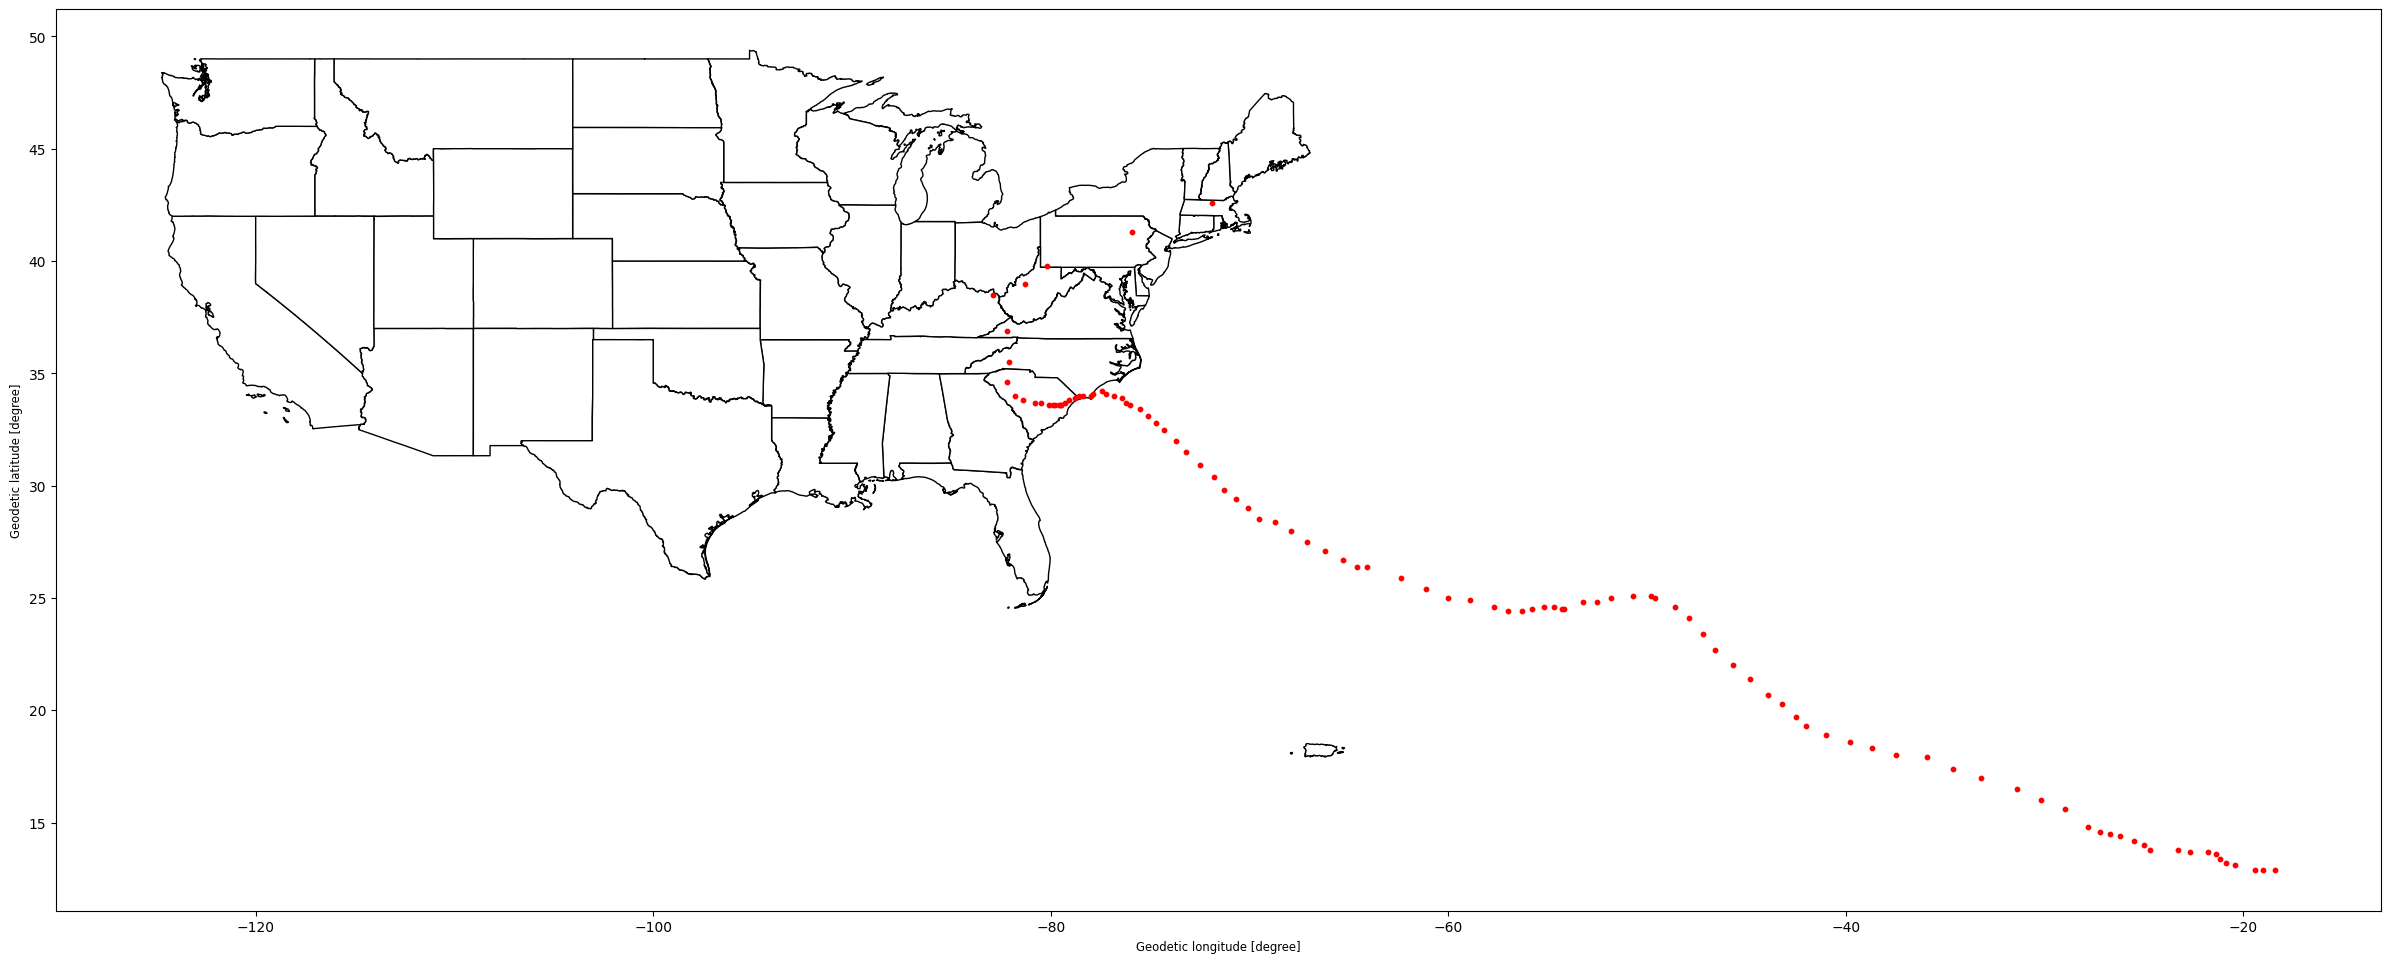

In [12]:
# Plot to see the hurricane overlay the US map, with the hurricane position on top
ax = country[~country.NAME.isin(["Alaska", "Hawaii"])].plot(figsize=(30, 20), color="white", edgecolor="black")
gdf_florence.plot(ax=ax, color="red", markersize=10)

**Q7) What is the coordinate reference system of the data?**

Check it for both layers, and say in a comment whether they match — two layers only line up on
one pair of axes if they share a crs.

In [13]:
# Affichage du CRS de chaque couche
print("CRS de la couche 'country' :", country.crs)
print("CRS de la couche 'gdf_florence' :", gdf_florence.crs)

# Commentaire : Les deux couches utilisent le CRS EPSG:4326 (WGS 84), elles correspondent donc parfaitement.

CRS de la couche 'country' : EPSG:4326
CRS de la couche 'gdf_florence' : EPSG:4326


**Q8) Which states did the hurricane pass through?**

```{hint}
One approach is to plot the trajectory over the US map, annotate each state with its name, and
read the answer off the figure. Other approaches are more than welcome — `overlay` with
`how="intersection"` will give you the track points that fall inside a state polygon, and the
`NAME` column of the result then answers the question directly.
```

In [ ]:
# Plot the US states without Alaska and Hawaii, then
# annotate the US states with their names, then
# select the hurricane trajectory points inside the US boundary with the overlay operation, then
# plot the hurricane trajectory inside the US boundary

ax = country[~country.NAME.isin(["Alaska", "Hawaii"])].plot(figsize=(30, 20), color="white", edgecolor="black").annotate.country.NAME
gdf_florence.plot(ax=ax, color="red", markersize=10)
gpd.overlay(country, gdf_florence, how="intersection").plot(ax=ax, color="red", markersize=10)

L'ouragan Florence est passé par les États suivants : ['North Carolina' 'South Carolina' 'Virginia' 'Kentucky' 'West Virginia'
 'Pennsylvania' 'Massachusetts']


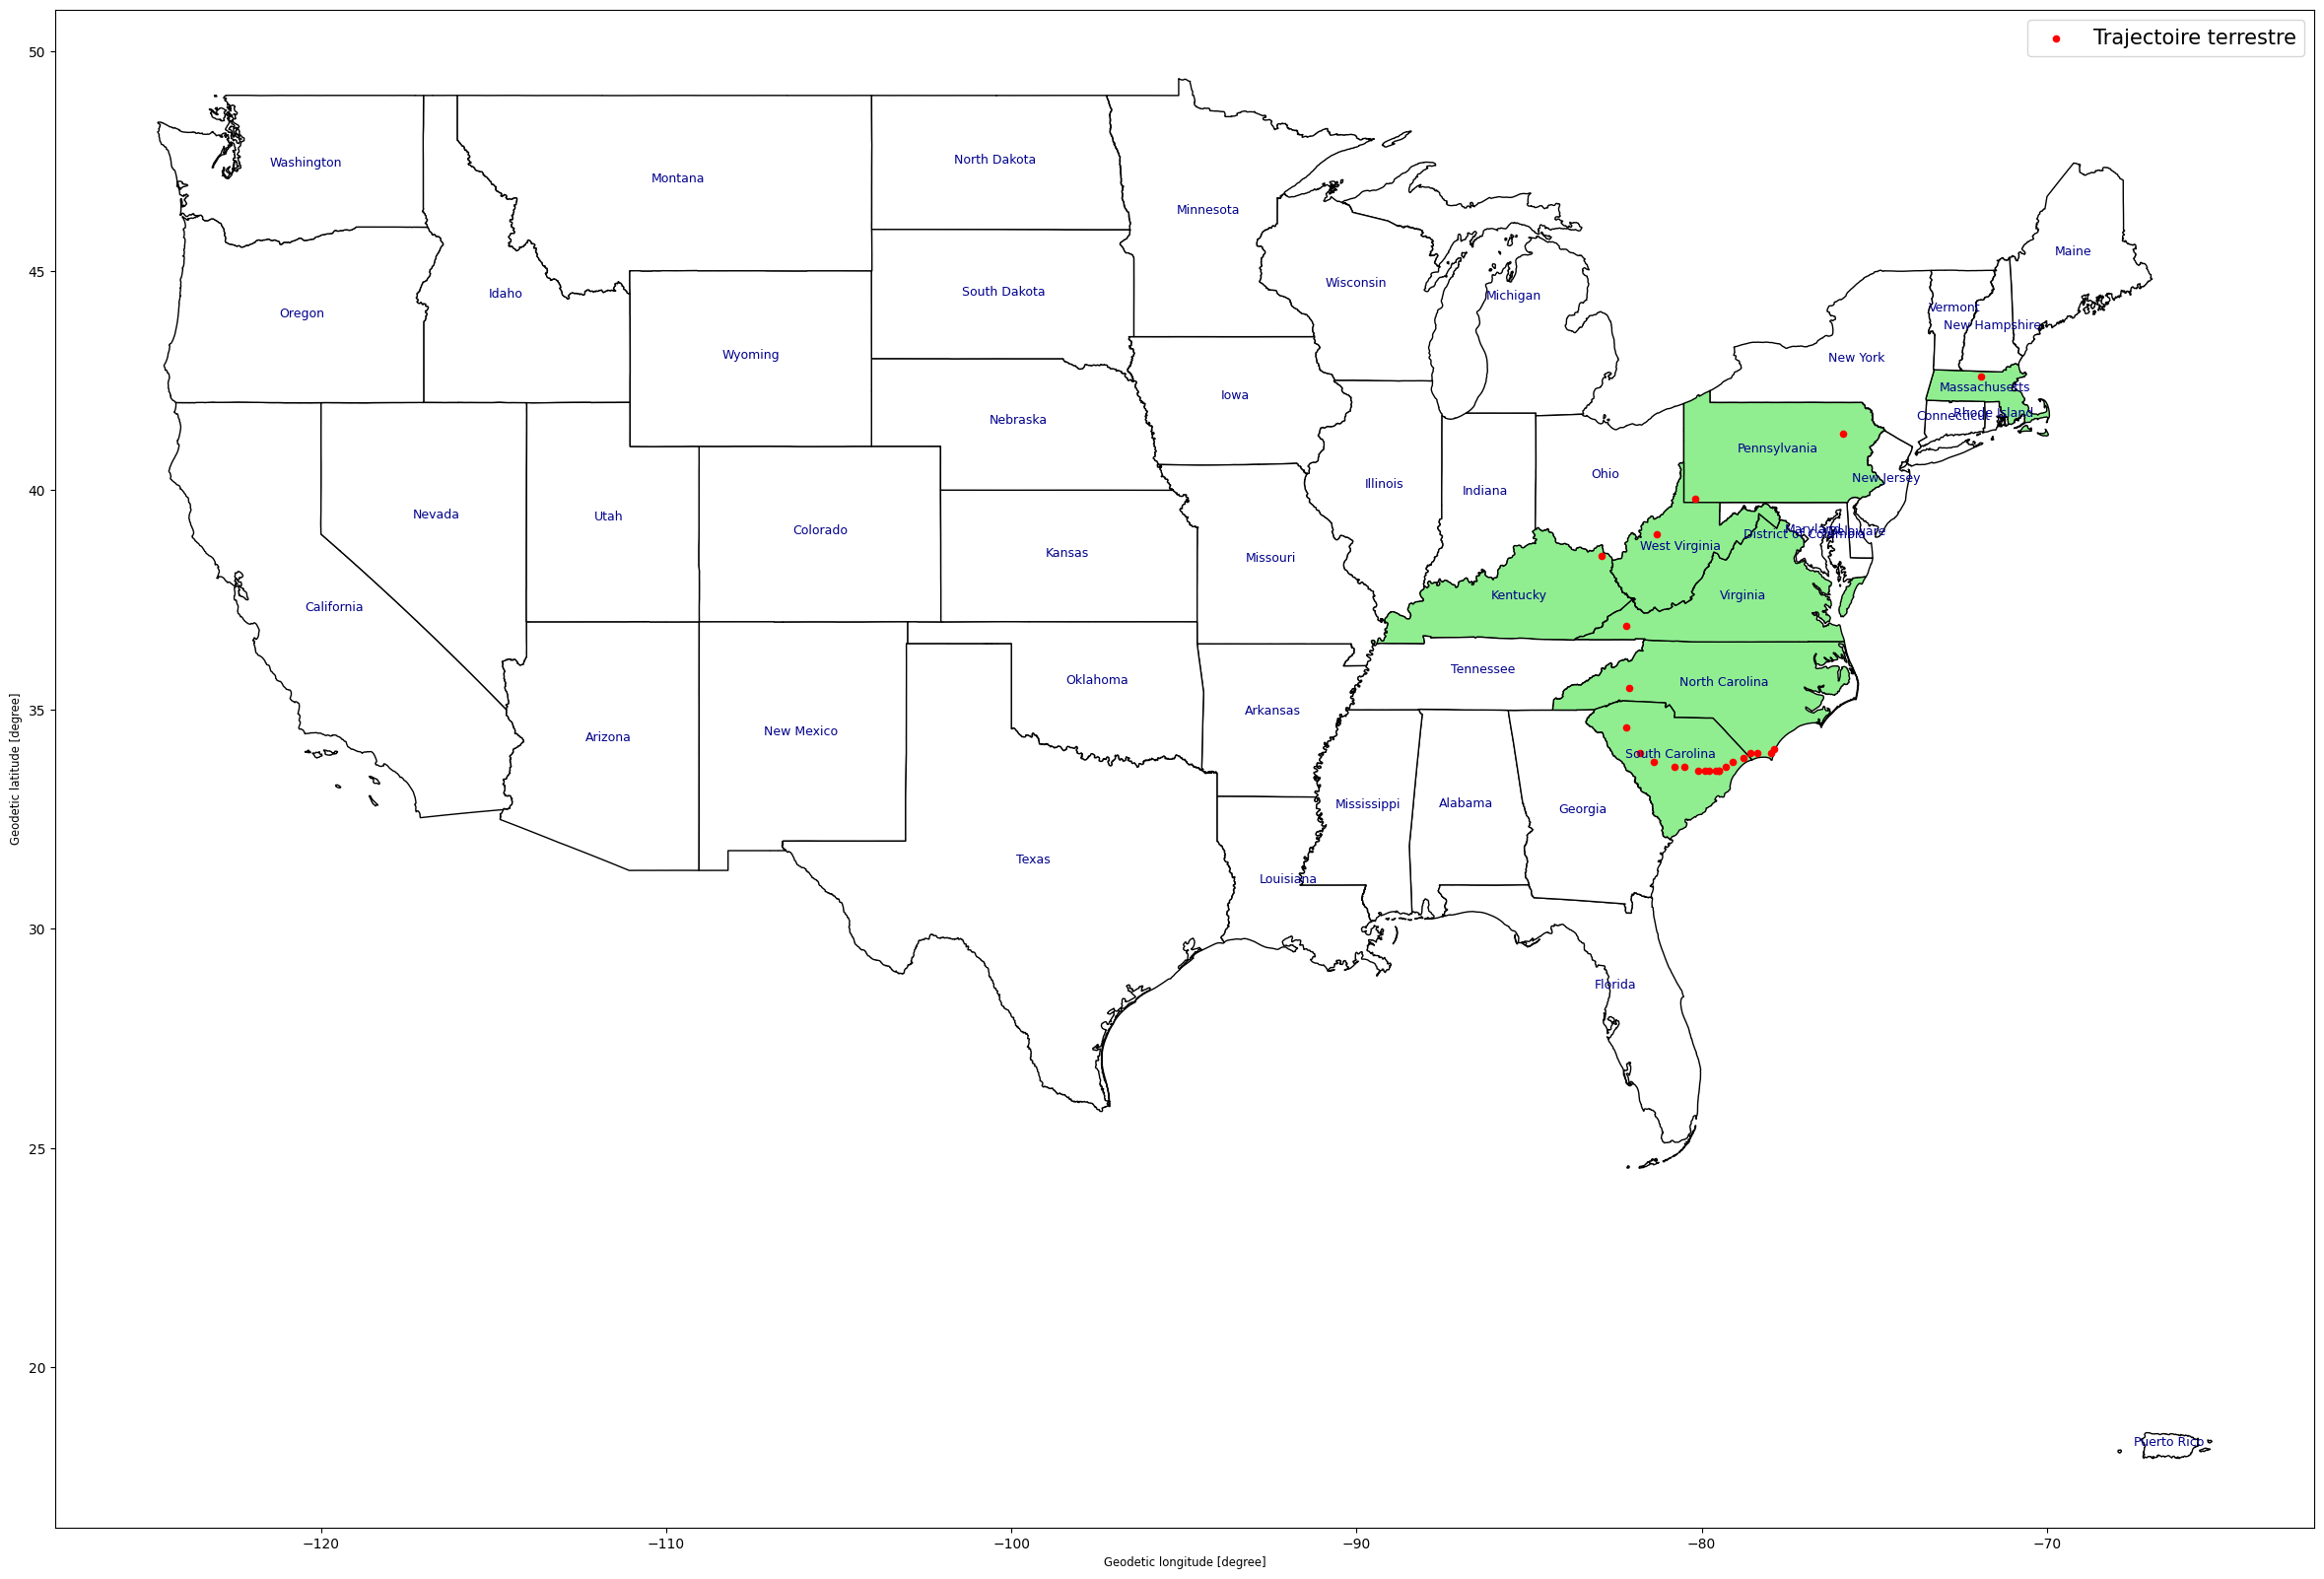

In [21]:
# 1. Filtrer les États continentaux
etats_continentaux = country[~country.NAME.isin(["Alaska", "Hawaii"])].copy()

# 2. Identifier les États traversés par l'ouragan à l'aide d'une jointure spatiale
points_interieur = gpd.sjoin(gdf_florence, etats_continentaux, how="inner", predicate="intersects")
etats_traverses = points_interieur["NAME"].unique()

# 3. Ajouter une colonne pour définir la couleur de chaque État
etats_continentaux["couleur"] = etats_continentaux["NAME"].apply(
    lambda x: "#90ee90" if x in etats_traverses else "white"
)

# 4. Tracer la carte avec les États traversés colorés et légendés
ax = etats_continentaux.plot(
    figsize=(30, 20),
    color=etats_continentaux["couleur"],
    edgecolor="black"
)

# 5. Annoter chaque État de manière simplifiée avec .apply()
etats_continentaux.apply(lambda row: ax.annotate(text=row.NAME, xy=(row.geometry.centroid.x, row.geometry.centroid.y), ha='center', fontsize=9, color="darkblue"), axis=1)

# 6. Tracer les points de la trajectoire sur terre
points_interieur.plot(ax=ax, color="red", markersize=20, label="Trajectoire terrestre")

# 7. Afficher les États traversés
print("L'ouragan Florence est passé par les États suivants :", etats_traverses)
plt.legend(loc="upper right", fontsize=15)
plt.show()

In [15]:
gpd.overlay(country, gdf_florence, how="intersection").plot(ax=ax, color="red", markersize=10)
plt.show()

/usr/local/lib/python3.13/dist-packages/geopandas/tools/overlay.py:386: UserWarning: `keep_geom_type=True` in overlay resulted in 25 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  result = _collection_extract(result, geom_type, keep_geom_type_warning)
/usr/local/lib/python3.13/dist-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)
